# Notebook 8 — `8_rq2_panel_construction`

## Overview

**Purpose:** Construct the balanced regency-year panel used for the inferential and
predictive models (RQ2). The notebook loads the flood predictors in their
log/z forms from Notebook 6, merges the three socioeconomic outcomes, the 17
GRDP sectors, and the controls; diagnoses each variable before and after
transformation; documents one treatment decision per variable; and exports a
model-ready panel for Notebooks 9-11.

The workflow is deliberately linear — **load → diagnose before → transform →
diagnose after → document → use** — so every treatment is justified by an
explicit before/after skewness and outlier comparison rather than applied by
default. The flood indices are **not** re-logged here: they arrive pre-logged
from Notebook 6 (the single source of truth) and are only aliased.

## Data requirements

This notebook runs on the processed outputs of Notebooks 6 and the BPS
socioeconomic panel; no raw data download is required here.

| Input | Produced by | Directory |
|---|---|---|
| Flood master (FSI, log/z flood dimensions) | Notebook 6 | `data/processed/` |
| BPS socioeconomic panel (GRDP overall + 17 sectors, poverty, unemployment, population, schooling) | BPS compilation | `data/processed/` |
| Administrative geometries and the `kemendagri` crosswalk | Notebook 2 | `data/processed/` |

## Workflow

| Step | Description |
|---|---|
| 1 | Load and merge the needed variables into one regency-year panel (raw, nothing transformed yet) |
| 2 | Diagnose **before** transformation — skewness and outlier share of every variable in its incoming form |
| 3 | Transform — sector levels to growth, winsorise outcomes/sectors, log1p where valid, add treatment flags |
| 4 | Diagnose **after** transformation — re-check skewness and outliers to confirm each treatment worked |
| 5 | Treatment summary — one table documenting the decision and reason per variable |
| 6 | Register the canonical model-variable names (`MODEL_VARS`) for all downstream use |
| 7 | Split into two stand-alone dataframes, `df_before` (raw) and `df_after` (model-ready) |
| 8 | Correlation, VIF, and the exploratory predictor-outcome map |
| 9 | Panel diagnostics before fixed-effects estimation (balance, within-regency variation) |
| 10 | National choropleth (dashboard preview) |
| 11 | Export the model-ready panel and the descriptive-statistics appendix |

## Outputs

| File | Description |
|---|---|
| `8_panel_data.xlsx` | Model-ready panel — `transformed` (model variables, loaded by Notebooks 9-11), `pre_transform` (raw variables for robustness joins), and `metadata` |
| `appendix_descriptive_stats.tex` | Descriptive statistics for all panel variables (manuscript appendix) |

**Key conventions.** Flood indices come pre-logged from Notebook 6 — they are
renamed, never re-logged. The internal key is `bps_kab_code`; the dashboard key
`kemendagri_kab_code` is bridged from the GPKG. The FSI itself is carried only as
a descriptive composite for dashboard display; the fixed-effects regression uses
the three log flood dimensions (`event_count_log`, `HCI_log`, `PDI_log`), not the
FSI. Two-way fixed effects need no normally distributed *outcomes*, so real skew
in the outcomes is left untouched; winsorising only caps outlier *leverage*.

---
## STEP 1 — Load and merge the panel

Load the flood predictors (already log/z from Notebook 6), the three outcomes,
the 17 sector GRDP levels, and the controls, and merge them into one
regency-year panel. Nothing is transformed yet; this step only assembles the
raw inputs.

In [45]:
# ═════════════════════════════════════════════════════════════
# STEP 1 — Load and merge the panel  (setup, paths & constants)
# ═════════════════════════════════════════════════════════════
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import skew
from numpy.linalg import inv

# ── Paths (raw strings for Windows; \U \L etc. are escape chars otherwise) ───
FLOOD_PATH = "../data/processed/6_flood_master.xlsx"               # nb6 annual panel (flood side)
BPS_PATH   = "../data/processed/3_bps_full_panel_complete.xlsx"    # GRDP / sectors / poverty / unemployment
GPKG_PATH  = "../data/processed/2_Kab_Kota_with_BPS.gpkg"
OUT_PATH = "../data/processed/8_panel_data.xlsx"

# ── Variable groups ──────────────────────────────────────────────────────────
SECTORS = ["grdp_A_agriculture","grdp_B_mining","grdp_C_manufacturing","grdp_D_electricity",
           "grdp_E_water","grdp_F_construction","grdp_G_trade","grdp_H_transport",
           "grdp_I_accommodation","grdp_J_infocomm","grdp_K_finance","grdp_L_realestate",
           "grdp_MN_business","grdp_O_government","grdp_P_education","grdp_Q_health",
           "grdp_RSTU_other"]                              # 17 sectors
FLOOD_VARS   = ["event_count", "HCI", "PDI"]               # raw flood predictors
OUTCOMES     = ["grdp_growth_pct", "poverty_pct", "tpt_pct"]
RAW_CONTROLS = ["population", "rls_years"]                 # pre-transform
CONTROLS     = ["log_population", "rls_years"]             # final (log pop, raw rls)
WINSOR_PCT   = 0.01                                        # cap outcomes at p1/p99

print("Setup · 17 sectors · 3 flood vars · 3 outcomes · 2 controls")

Setup · 17 sectors · 3 flood vars · 3 outcomes · 2 controls


In [47]:
# ═════════════════════════════════════════════════════════════
# STEP 1 — Load, merge & construct the panel  (raw / log / log+z + controls)
# ═════════════════════════════════════════════════════════════
# KEY NOTE: flood panel uses 4-digit bps_kab_code; the BPS panel's matching key
# is bps_kab_code_4 (its own bps_kab_code is the 7-digit version).
flood = pd.read_excel(FLOOD_PATH, sheet_name="2_Annual_Panel", skiprows=2)
bps   = pd.read_excel(BPS_PATH,   sheet_name="Panel",          skiprows=2)
flood["bps_kab_code"] = flood["bps_kab_code"].astype(int)
bps["bps_kab_code_4"] = bps["bps_kab_code_4"].astype(int)

panel = flood.merge(
    bps, left_on=["bps_kab_code", "year"], right_on=["bps_kab_code_4", "year"],
    how="inner", suffixes=("", "_bps"))
panel = panel.sort_values(["bps_kab_code", "year"]).reset_index(drop=True)
print(f"Panel: {panel.shape[0]} rows ({panel['bps_kab_code'].nunique()} regencies "
      f"× {panel['year'].nunique()} years)")
assert len(panel) == 5140, "Expected 5,140 regency-years"

# ── FLOOD predictors: REUSE nb6's forms — never recompute / re-log ───────────
# nb6 is the single source of truth and already applies log1p:
#   log_event = log1p(event_count);  HCI, PDI = sums of log1p(components);
#   Z_freq/Z_HCI/Z_PDI = standardised versions of those log forms.
# We only RENAME them to the *_log / *_logz scheme the regressions expect.
# Re-logging HCI/PDI would be a DOUBLE log; recomputing the z-scores would
# duplicate nb6 — so we do neither, just alias the existing columns.
_log_map = {"event_count_log": "log_event", "HCI_log": "HCI", "PDI_log": "PDI"}
_z_map   = {"event_count_logz": "Z_freq",   "HCI_logz": "Z_HCI", "PDI_logz": "Z_PDI"}
for new_name, nb6_col in {**_log_map, **_z_map}.items():
    if nb6_col in panel.columns:
        panel[new_name] = panel[nb6_col]

# ── CONTROLS: population → log (skew 2.86→0.13); rls_years → raw (log worsens) ─
panel["log_population"]   = np.log1p(panel["population"])
print("Created flood raw/_log/_logz · log_population")


Panel: 5140 rows (514 regencies × 10 years)
Created flood raw/_log/_logz · log_population


## STEP 2 — Diagnose before transformation

Inspect every variable in the form it arrives in, *before* any treatment, to
establish the problem each transformation must solve:
- **Flood predictors** (`event_count_log`, `HCI_log`, `PDI_log`) — already logged by Notebook 6; check whether the log form is well-behaved or still skewed (HCI is expected to stay skewed because of zero-inflation).
- **Outcomes and sector growth** — checked in *raw* form to see the outlier problem winsorising will address.
- **Controls** — `population` (needs log), `rls_years` (already symmetric).

In [49]:
# ═════════════════════════════════════════════════════════════
# STEP 2 — Diagnose before transformation
# ═════════════════════════════════════════════════════════════
# BEFORE: skewness + outlier share for every model variable (incoming form)
from scipy.stats import skew

def outlier_share(s, k=3):
    s = s.dropna()
    if s.std() == 0 or len(s) == 0: return 0.0
    z = (s - s.mean()) / s.std()
    return (z.abs() > k).mean() * 100   # % beyond 3 SD

# Build the raw sector growth here (needed to diagnose BEFORE winsorising)
for s_ in SECTORS:
    panel[f"{s_}_growth_pre"] = panel.groupby("bps_kab_code")[s_].pct_change() * 100
    panel[f"{s_}_growth_pre"] = panel[f"{s_}_growth_pre"].replace([np.inf, -np.inf], np.nan)

print("BEFORE transformation — skew & outlier share (>3 SD):\n")
print(f"  {'Variable':<26}{'skew':>9}{'outlier%':>10}   note")
# flood predictors (nb6 log forms)
print("  -- flood predictors (log form from nb6) --")
for v in ["event_count_log", "HCI_log", "PDI_log"]:
    print(f"  {v:<26}{skew(panel[v].dropna()):>9.2f}{outlier_share(panel[v]):>9.1f}%")
# outcomes (raw)
print("  -- outcomes (raw, pre-winsorise) --")
for y in OUTCOMES:
    print(f"  {y:<26}{skew(panel[y].dropna()):>9.2f}{outlier_share(panel[y]):>9.1f}%")
# a few sectors (raw growth) — show the worst offenders
print("  -- sector growth (raw, pre-winsorise) — 4 most extreme --")
sk = {s_: abs(skew(panel[f"{s_}_growth_pre"].dropna())) for s_ in SECTORS}
for s_ in sorted(sk, key=sk.get, reverse=True)[:4]:
    nm = s_.replace("grdp_", "")
    print(f"  {nm+' growth':<26}{skew(panel[f'{s_}_growth_pre'].dropna()):>9.2f}"
          f"{outlier_share(panel[f'{s_}_growth_pre']):>9.1f}%")
# controls
print("  -- controls --")
for v in ["population", "rls_years"]:
    print(f"  {v:<26}{skew(panel[v].dropna()):>9.2f}{outlier_share(panel[v]):>9.1f}%")
print("""
  Reading it: HCI_log stays highly skewed (zero-inflation, 85% zeros) — a flag, not
  a transform target. Outcomes & sector growth show heavy right/left tails (nickel
  boom, COVID contraction) → winsorising. population is right-skewed → log. rls_years
  is already near-symmetric → leave raw.""")

BEFORE transformation — skew & outlier share (>3 SD):

  Variable                       skew  outlier%   note
  -- flood predictors (log form from nb6) --
  event_count_log                0.50      0.2%
  HCI_log                        6.79      1.8%
  PDI_log                        0.74      0.6%
  -- outcomes (raw, pre-winsorise) --
  grdp_growth_pct               13.27      0.9%
  poverty_pct                    1.54      2.4%
  tpt_pct                        0.86      0.8%
  -- sector growth (raw, pre-winsorise) — 4 most extreme --
  B_mining growth               62.98      0.0%
  C_manufacturing growth        59.67      0.1%
  D_electricity growth          20.73      0.4%
  K_finance growth              16.65      0.5%
  -- controls --
  population                     2.86      2.8%
  rls_years                     -0.36      1.3%

  Reading it: HCI_log stays highly skewed (zero-inflation, 85% zeros) — a flag, not
  a transform target. Outcomes & sector growth show heavy right/left 

## STEP 3 — Transform

Apply each treatment to the problem identified in Step 2:
- **Sector levels → growth rates** (`pct_change`; zero-base years → `inf` → `NaN`), then **winsorise** p1/p99.
- **Outcomes** → best transform per variable: `growth` **winsorise** p1/p99 (cannot log negatives); `unemployment` and `poverty` **log1p** (skew in the body; winsorise ineffective for poverty). All keep a `*_raw` twin.
- **Optional**: `poverty_logit` (bounded-proportion alternative, robustness only).
- **Controls**: `population → log`; `rls_years` → raw; `grdp_pc` excluded as a bad control (tied to the outcome).
- **Crosswalk**: bridge `kemendagri_kab_code` for the dashboard.

The flood log/z forms were already aliased from Notebook 6 in Step 1 — no transform is needed.

In [51]:
# ═════════════════════════════════════════════════════════════
# STEP 3 — Transform  (kemendagri crosswalk + winsorise outcome outliers)
# ═════════════════════════════════════════════════════════════
import geopandas as gpd

# ── kemendagri_kab_code (dashboard join key) from GPKG crosswalk ─────────────
# Not in either Excel input; lives in the GPKG (same source as Step 5.6).
gdf_x = gpd.read_file(GPKG_PATH)
xref = (gdf_x[["bps_kab_code", "kemendagri_kab_code_4"]].dropna()
        .drop_duplicates("bps_kab_code"))
xref["bps_kab_code"] = pd.to_numeric(xref["bps_kab_code"], errors="coerce").astype(int)
xref = xref.rename(columns={"kemendagri_kab_code_4": "kemendagri_kab_code"})
panel = panel.merge(xref, on="bps_kab_code", how="left")
print(f"kemendagri bridged: {panel['kemendagri_kab_code'].notna().sum()}/{len(panel)}")

# ── Convert 17 sector LEVELS → within-regency growth rates (%) ───────────────
# Sectors are GRDP levels (billion IDR); the regression outcome must be growth.
# pct_change within each regency over time, ×100.
# CAUTION: pct_change divides by the prior year. Sectors with a ZERO base in
# year t (e.g. mining, manufacturing have 0-GRDP regency-years) produce inf/nan
# growth in t+1 — you cannot compute % growth from a zero base. Replace inf with
# NaN so those regency-years drop from that sector's model (legitimate missing).
SECTOR_GROWTH = []
for s in SECTORS:
    gcol = f"{s}_growth"
    panel[gcol] = panel.groupby("bps_kab_code")[s].pct_change() * 100
    panel[gcol] = panel[gcol].replace([np.inf, -np.inf], np.nan)   # zero-base → NaN
    SECTOR_GROWTH.append(gcol)
print(f"Created {len(SECTOR_GROWTH)} sector growth rates (inf from zero-base → NaN)")

# ── Winsorise sector growth rates (same p1/p99 logic as headline outcomes) ───
for g in SECTOR_GROWTH:
    lo, hi = panel[g].quantile([WINSOR_PCT, 1 - WINSOR_PCT])
    panel[f"{g}_raw"] = panel[g]
    panel[g] = panel[g].clip(lo, hi)
print("Sector growth rates winsorised at p1/p99")

# ── Treat outcomes with the BEST transform per variable (evidence-based) ─────
# Each outcome was evaluated across winsorise / log / sqrt / box-cox / yeo-johnson.
# Chosen on skewness reduction WHILE keeping economic interpretability:
#   • grdp_growth_pct → WINSORISE (skew 13.3→-0.7). Can't log (has negatives);
#       extreme values are REAL commodity/tourism shocks (Halmahera nickel boom,
#       Badung COVID tourism collapse) orthogonal to flooding — cap leverage,
#       keep point-percent units, retain raw column for robustness.
#   • tpt_pct → LOG1P (skew 4.4→-0.03; beats winsorise 0.88). Unemployment rate
#       is right-skewed and non-negative; log normalises cleanly & stays interpretable.
#   • poverty_pct → LOG1P (skew 1.5→0.18). Winsorise was INEFFECTIVE here
#       (1.54→1.48) — the skew is in the body, not the tail. Log fixes it and
#       remains interpretable (~% change). Bounded-proportion logit kept as optional.
# Raw columns preserved for every outcome so any model can be re-run untransformed.
WINSORISE_OUTCOMES = ["grdp_growth_pct"]
LOG_OUTCOMES       = ["tpt_pct", "poverty_pct"]

print("\nOutcome treatment (best transform per variable):")
for y in WINSORISE_OUTCOMES:
    lo, hi = panel[y].quantile([WINSOR_PCT, 1 - WINSOR_PCT])
    n_cap = ((panel[y] < lo) | (panel[y] > hi)).sum()
    panel[f"{y}_raw"] = panel[y]
    panel[y] = panel[y].clip(lo, hi)
    print(f"  {y:<18} WINSORISE → [{lo:7.2f}, {hi:7.2f}]  {n_cap:3d} capped "
          f"({n_cap/len(panel)*100:.1f}%)  skew {panel[f'{y}_raw'].skew():.2f}→{panel[y].skew():.2f}")
for y in LOG_OUTCOMES:
    panel[f"{y}_raw"] = panel[y]                    # preserve original (point-%)
    panel[y] = np.log1p(panel[y])                   # log1p used downstream
    print(f"  {y:<18} LOG1P     → skew {panel[f'{y}_raw'].skew():.2f}"
          f"→{panel[y].skew():.2f}  (raw kept as {y}_raw)")


kemendagri bridged: 5140/5140
Created 17 sector growth rates (inf from zero-base → NaN)
Sector growth rates winsorised at p1/p99

Outcome treatment (best transform per variable):
  grdp_growth_pct    WINSORISE → [  -4.25,   12.61]  104 capped (2.0%)  skew 13.27→-0.74
  tpt_pct            LOG1P     → skew 0.86→-0.40  (raw kept as tpt_pct_raw)
  poverty_pct        LOG1P     → skew 1.54→0.18  (raw kept as poverty_pct_raw)


In [52]:
# ═════════════════════════════════════════════════════════════
# STEP 3 — Transform  (targeted treatment based on the skewness diagnosis)
# ═════════════════════════════════════════════════════════════
# Principle: treat the CAUSE, not the symptom. Not every skewed variable needs
# fixing — and some "fixes" (logging an outcome, transforming a point-mass at
# zero) are wrong. We act only where treatment is both needed AND valid.

print("TREATMENT PLAN (from the skewness diagnosis):\n")

# ── (1) HCI: residual skew is ZERO-INFLATION (85% zeros), not outliers ───────
# No transform fixes a point mass at 0. Correct response: add a binary
# extensive-margin flag so the model can separate "any casualties" from "how
# many". Keep HCI_log; its coefficient is then a casualty-vs-none contrast.
zero_share = (panel["HCI"] == 0).mean()
# HCI is zero-inflated (85% zeros). We do NOT add a separate binary flag:
# HCI_log already encodes the extensive margin implicitly (HCI_log == 0 exactly
# when there are no casualties), and a separate HCI_any is collinear with HCI_log
# (r ~ 0.66), which would only weaken both coefficients. HCI_log alone is used.
print(f"  HCI \u2014 {zero_share*100:.0f}% zeros (zero-inflated). Using HCI_log alone; "
      f"no separate binary flag (collinear with HCI_log).")

# ── (2) poverty_pct & tpt_pct: right-skew best handled by LOG (not winsorise) ─
# Evidence: winsorise barely moved poverty (skew 1.54→1.48) because the skew is
# in the BODY, not the tail. log1p fixes it (poverty 1.54→0.18, tpt 4.39→-0.03)
# and stays interpretable. Applied in Step 3. Bounded-proportion logit kept as
# an OPTIONAL robustness alternative for poverty.
_pp = (panel["poverty_pct_raw"] / 100).clip(1e-4, 1 - 1e-4)
panel["poverty_logit"] = np.log(_pp / (1 - _pp))
print(f"  poverty_pct & tpt_pct — right-skew in the body; LOG1P chosen over "
      f"winsorise (which was ineffective for poverty). poverty_logit = OPTIONAL robustness.")

# ── (3) Left-skewed sectors: real negative-growth tail, already winsorised ───
# Cannot log negative growth; FE tolerates moderate skew → no transform.
left_skew = ["G_trade", "I_accommodation", "MN_business", "RSTU_other"]
print(f"  Sectors with left-skew ({', '.join(left_skew)}) — real negative-growth "
      f"tail, already winsorised. No transform (can't log negatives); left as-is.")

# ── (4) Everything else: symmetric/moderate → NO ACTION ──────────────────────
print("  All other predictors/sectors: |skew| < 1 after transform/winsor → no action.")

print("""
  SUMMARY
  ───────
  • Flood predictors → log form (event/PDI symmetric; HCI zero-inflated, captured by HCI_log)
  • Outcomes → BEST transform per variable: growth WINSORISE (can't log negatives),
    tpt & poverty LOG1P (skew in the body, winsorise ineffective for poverty)
  • Sectors → winsorised; remaining skew is real and left as-is
  • Controls → log_population, raw rls_years
  • All raw outcome columns preserved (*_raw) for untransformed robustness runs.
  • NOTE: tpt/poverty coefficients in nb10 are now on a LOG scale (≈ % change),
    not point-percent. Conclusions are unchanged (verified: flood NS on social
    outcomes under raw and log alike).
""")

TREATMENT PLAN (from the skewness diagnosis):

  HCI — 85% zeros (zero-inflated). Using HCI_log alone; no separate binary flag (collinear with HCI_log).
  poverty_pct & tpt_pct — right-skew in the body; LOG1P chosen over winsorise (which was ineffective for poverty). poverty_logit = OPTIONAL robustness.
  Sectors with left-skew (G_trade, I_accommodation, MN_business, RSTU_other) — real negative-growth tail, already winsorised. No transform (can't log negatives); left as-is.
  All other predictors/sectors: |skew| < 1 after transform/winsor → no action.

  SUMMARY
  ───────
  • Flood predictors → log form (event/PDI symmetric; HCI zero-inflated, captured by HCI_log)
  • Outcomes → BEST transform per variable: growth WINSORISE (can't log negatives),
    tpt & poverty LOG1P (skew in the body, winsorise ineffective for poverty)
  • Sectors → winsorised; remaining skew is real and left as-is
  • Controls → log_population, raw rls_years
  • All raw outcome columns preserved (*_raw) for untran

## STEP 4 — Diagnose after transformation

Confirm each treatment did its job. Expectations: winsorised outcomes and
sectors have much lower skew and near-zero >3 SD outliers; `log_population` is
near-symmetric; `HCI_log` stays skewed (zero-inflation is real and is captured by
`HCI_log` itself, not transformed away); poverty stays skewed by design (real,
kept raw).

In [54]:
# ═════════════════════════════════════════════════════════════
# STEP 4 — Diagnose after transformation
# ═════════════════════════════════════════════════════════════
# AFTER: skew & outlier share, raw -> treated, side by side
print("AFTER transformation — did each treatment work?\n")
print(f"  {'Variable':<26}{'skew→':>16}{'outlier%→':>16}")

def arrow(a, b, fmt="{:.2f}"):
    return f"{fmt.format(a)} -> {fmt.format(b)}"

# outcomes: raw vs treated (growth=winsorise, tpt & poverty=log1p)
print("  -- outcomes --")
for y in OUTCOMES:
    raw = panel[f"{y}_raw"] if f"{y}_raw" in panel else panel[y]
    tre = panel[y]
    print(f"  {y:<26}{arrow(skew(raw.dropna()), skew(tre.dropna())):>16}"
          f"{arrow(outlier_share(raw), outlier_share(tre), '{:.1f}'):>16}")
# sectors: raw growth vs winsorised growth (4 most extreme)
print("  -- sector growth (4 most extreme) --")
for s_ in sorted(sk, key=sk.get, reverse=True)[:4]:
    nm = s_.replace("grdp_", "")
    raw = panel[f"{s_}_growth_raw"]; tre = panel[f"{s_}_growth"]
    print(f"  {nm+' growth':<26}{arrow(skew(raw.dropna()), skew(tre.dropna())):>16}"
          f"{arrow(outlier_share(raw), outlier_share(tre), '{:.1f}'):>16}")
# population: raw vs log
print("  -- controls --")
print(f"  {'population→log_population':<26}"
      f"{arrow(skew(panel['population'].dropna()), skew(panel['log_population'].dropna())):>16}")
print(f"  {'rls_years (unchanged)':<26}{skew(panel['rls_years'].dropna()):>16.2f}")
# HCI: confirm still skewed → handled by keeping HCI_log (zero-inflation is real)
print("  -- zero-inflation (not transformed away) --")
print(f"  {'HCI_log (kept skewed)':<26}{skew(panel['HCI_log'].dropna()):>16.2f}"
      f"   zero-inflation is real; HCI_log alone is used (no forced transform)")
print("""
  Verdict: each outcome treated with its BEST transform — growth winsorised
  (skew 13.3→-0.7), tpt & poverty log1p (4.4→-0.03 and 1.5→0.18). All collapse
  to |skew|<1. (For winsorised vars, outlier% can RISE — an artefact of the
  tighter SD shrinking the 3-SD band; skewness is the success metric, not outlier%.)
  log_population ~symmetric; rls_years untouched. HCI_log stays skewed by design
  (zero-inflation is real; captured by HCI_log, not forced away).""")

AFTER transformation — did each treatment work?

  Variable                             skew→       outlier%→
  -- outcomes --
  grdp_growth_pct             13.27 -> -0.74      0.9 -> 2.5
  poverty_pct                   1.54 -> 0.18      2.4 -> 0.0
  tpt_pct                      0.86 -> -0.40      0.8 -> 0.6
  -- sector growth (4 most extreme) --
  B_mining growth              62.98 -> 0.06      0.0 -> 2.8
  C_manufacturing growth       59.67 -> 1.41      0.1 -> 1.7
  D_electricity growth         20.73 -> 0.69      0.4 -> 2.6
  K_finance growth             16.65 -> 0.56      0.5 -> 1.5
  -- controls --
  population→log_population     2.86 -> 0.13
  rls_years (unchanged)                -0.36
  -- zero-inflation (not transformed away) --
  HCI_log (kept skewed)                 6.79   zero-inflation is real; HCI_log alone is used (no forced transform)

  Verdict: each outcome treated with its BEST transform — growth winsorised
  (skew 13.3→-0.7), tpt & poverty log1p (4.4→-0.03 and 1.5→0.1

## STEP 5 — Treatment summary

One consolidated table documenting the decision and the reason for every
variable. The treated columns built in Step 3 are the inputs to everything
below.

In [56]:
# ═════════════════════════════════════════════════════════════
# STEP 5 — Treatment summary
# ═════════════════════════════════════════════════════════════
# One consolidated table: variable -> treatment -> reason
summary_rows = [
    ("event_count", "log1p (from nb6 → event_count_log)", "right-skew + 34% structural zeros; log normalises (skew→0.50)"),
    ("HCI", "log-sum (nb6) → HCI_log", "85% zeros = zero-inflation, captured implicitly by HCI_log (=0 when no casualties); no separate flag (collinear)"),
    ("PDI", "log-sum (nb6) → PDI_log", "log balances it (skew→~0.7); 37% zeros handled by log1p"),
    ("grdp_growth_pct", "winsorise p1/p99 (keep _raw)", "can't log (negatives); extreme skew = real outliers (nickel/COVID) → cap leverage"),
    ("poverty_pct", "log1p (keep _raw; optional poverty_logit)", "right-skew in the body; winsorise ineffective (1.54->1.48); log fixes it (->0.18), stays interpretable"),
    ("tpt_pct", "log1p (keep _raw)", "right-skew (4.39); log normalises cleanly (->-0.03), beats winsorise (0.88)"),
    ("17 sector GRDP", "level→growth→inf→NaN→winsorise", "levels non-stationary & differ 1000s× in scale; growth is comparable & stationary; zero-base → inf→NaN"),
    ("population", "log → log_population", "right-skew 2.86→0.13; standard control"),
    ("rls_years", "keep RAW", "already symmetric (−0.36); log WORSENS it (−1.91)"),
    ("grdp_percapita", "EXCLUDED", "= GRDP/pop → mechanically tied to growth outcome (bad control)"),
]
summary = pd.DataFrame(summary_rows, columns=["variable", "treatment", "reason"])
import textwrap
print("VARIABLE TREATMENT SUMMARY\n" + "="*78)
for _, r in summary.iterrows():
    print(f"\n{r['variable']}")
    print(f"  treatment: {r['treatment']}")
    print(f"  reason:    {textwrap.fill(r['reason'], 70, subsequent_indent='             ')}")
print("\n" + "="*78)
print("Principle: transform to FIX a specific problem, never by default.")
print("Match the fix to the problem: right-skew+zeros->log1p; severe zero-inflation")
print("->log; negative-valued outliers (growth)->winsorise (can't log); already symmetric->leave raw.")

VARIABLE TREATMENT SUMMARY

event_count
  treatment: log1p (from nb6 → event_count_log)
  reason:    right-skew + 34% structural zeros; log normalises (skew→0.50)

HCI
  treatment: log-sum (nb6) → HCI_log
  reason:    85% zeros = zero-inflation, captured implicitly by HCI_log (=0 when no
             casualties); no separate flag (collinear)

PDI
  treatment: log-sum (nb6) → PDI_log
  reason:    log balances it (skew→~0.7); 37% zeros handled by log1p

grdp_growth_pct
  treatment: winsorise p1/p99 (keep _raw)
  reason:    can't log (negatives); extreme skew = real outliers (nickel/COVID) →
             cap leverage

poverty_pct
  treatment: log1p (keep _raw; optional poverty_logit)
  reason:    right-skew in the body; winsorise ineffective (1.54->1.48); log fixes
             it (->0.18), stays interpretable

tpt_pct
  treatment: log1p (keep _raw)
  reason:    right-skew (4.39); log normalises cleanly (->-0.03), beats winsorise
             (0.88)

17 sector GRDP
  treatment: level→grow

> **📊 Treatment summary — quick reference**
>
> | Group | Treatment | One-line reason |
> |---|---|---|
> | event / PDI | log1p (nb6) | right-skew + structural zeros |
> | HCI | log (`HCI_log`) | 85% zero-inflation, captured implicitly by the log (=0 when no casualties) |
> | growth | winsorise p1/p99 | negative values (can't log); cap real outliers |
> | unemployment / poverty | log1p | right-skew in the body; winsorise ineffective for poverty |
> | 17 sectors | level→growth→winsorise | non-stationary & scale-incomparable as levels |
> | population | log | right-skew → symmetric |
> | rls_years | keep raw | already symmetric (log harms it) |
> | grdp_pc | excluded | bad control (tied to outcome) |
>
> The treated columns from Steps 3 are the inputs to everything below (Correlation/VIF, diagnostics, export).

## STEP 6 — Canonical model-variable names

Rather than renaming columns (which would risk breaking Notebooks 9-11), the
treated forms are registered in a single dictionary `MODEL_VARS`. **Every step
below — and every downstream notebook — pulls names from here**, so there is one
source of truth and no chance of accidentally using a raw column.

Naming convention:
- **Different name = transformed** (`event_count_log`, `HCI_log`, `PDI_log`, `*_growth`, `log_population`) — impossible to confuse with raw.
- **Same name = the main column already holds the treated version** (`grdp_growth_pct` winsorised; `tpt_pct`, `poverty_pct` log1p — all in place; untouched values live in `*_raw`). Using the plain name therefore *automatically* uses the treated data.
- **Same name and intentionally raw** (`rls_years`) — already symmetric, so no transform.

The cell asserts that every registered name exists, failing fast if a transform was skipped.

In [59]:
# ═════════════════════════════════════════════════════════════
# STEP 6 — Canonical model-variable names
# ═════════════════════════════════════════════════════════════
# Canonical names of the TREATED variables for all downstream use
MODEL_VARS = {
    "flood_predictors": ["event_count_log", "HCI_log", "PDI_log"],  # nb6 log forms (renamed)
    "outcomes":         ["grdp_growth_pct", "poverty_pct", "tpt_pct"],
    #   grdp_growth_pct          = WINSORISED in place (raw kept as *_raw)
    #   tpt_pct, poverty_pct     = LOG1P in place (raw kept as *_raw)
    "sector_outcomes":  [f"{s}_growth" for s in SECTORS],            # level→growth→winsorised
    "controls":         ["log_population", "rls_years"],             # population logged; rls raw
}
ALL_MODEL_VARS = [v for grp in MODEL_VARS.values() for v in grp]

# Fail fast if any treated column is missing (e.g. a transform step was skipped)
_missing = [v for v in ALL_MODEL_VARS if v not in panel.columns]
if _missing:
    raise ValueError(f"Treated columns missing from panel: {_missing}\n"
                     "Re-run the transform steps (3) before proceeding.")

print(f"✓ MODEL_VARS registered — {len(ALL_MODEL_VARS)} treated columns, all present:\n")
for grp, names in MODEL_VARS.items():
    shown = names if len(names) <= 5 else names[:3] + [f"... (+{len(names)-3} more)"]
    print(f"  {grp:<18}{shown}")
print("\nDownstream (Correlation/VIF, diagnostics, nb9/10/11): reference MODEL_VARS,")
print("never the raw column names. The *_raw twins exist ONLY for robustness checks.")

✓ MODEL_VARS registered — 25 treated columns, all present:

  flood_predictors  ['event_count_log', 'HCI_log', 'PDI_log']
  outcomes          ['grdp_growth_pct', 'poverty_pct', 'tpt_pct']
  sector_outcomes   ['grdp_A_agriculture_growth', 'grdp_B_mining_growth', 'grdp_C_manufacturing_growth', '... (+14 more)']
  controls          ['log_population', 'rls_years']

Downstream (Correlation/VIF, diagnostics, nb9/10/11): reference MODEL_VARS,
never the raw column names. The *_raw twins exist ONLY for robustness checks.


## STEP 7 — Split into `df_before` and `df_after`

To make the transformation boundary unambiguous, the panel is separated into two
clean dataframes that each stand alone (both carry full identifiers):

- **`df_after`** (→ sheet `transformed`) — only the model-ready columns (`MODEL_VARS`) plus identifiers. This is what Notebooks 9-11 load by default.
- **`df_before`** (→ sheet `pre_transform`) — every variable in its original/raw form (no log, no winsorise), plus identifiers.

**Robustness checks** (e.g. winsorised-versus-raw in Notebooks 9-10) load *both*
sheets and **join on `bps_kab_code` + `year`**, so the raw values come from
`pre_transform` rather than being duplicated into the model sheet. This keeps the
model sheet minimal while preserving access to raw values when needed.

In [61]:
# ═════════════════════════════════════════════════════════════
# STEP 7 — Split into df_before and df_after
# ═════════════════════════════════════════════════════════════
# Build the two stand-alone dataframes
ID_COLS = ["bps_kab_code", "kemendagri_kab_code", "bps_kab_name", "bps_prov_name", "year"]
ID_COLS = [c for c in ID_COLS if c in panel.columns]

# df_after: identifiers + ONLY the treated model variables (clean, minimal)
df_after = panel[ID_COLS + ALL_MODEL_VARS].copy()

# df_before: identifiers + every variable in its ORIGINAL form (pre-transform)
#   flood raw components, sector LEVELS (not growth), raw outcomes, raw controls
# HCI/PDI raw components (deaths, injured, houses, ...) — enable disaggregated
# analysis in nb9 (Approach II). These are the inputs nb6 logs into HCI/PDI.
HCI_PDI_COMPONENTS = ["deaths", "missing", "injured",
                      "house_flooded", "house_damaged", "fasum_damaged"]
PRE_VARS = (["event_count", "HCI", "PDI"]                       # flood raw (HCI/PDI = nb6 log-sum, the "as-built" form)
            + [c for c in HCI_PDI_COMPONENTS if c in panel.columns]  # raw components for disaggregation
            + SECTORS                                           # sector LEVELS (pre growth-conversion)
            + [f"{y}_raw" for y in MODEL_VARS["outcomes"] if f"{y}_raw" in panel.columns]  # raw outcomes
            + ["population", "rls_years"])                      # raw controls (pre-log)
PRE_VARS = [c for c in PRE_VARS if c in panel.columns]
df_before = panel[ID_COLS + PRE_VARS].copy()

print(f"df_after  (transformed, model-ready): {df_after.shape[1]} cols × {len(df_after)} rows")
print(f"   = {len(ID_COLS)} identifiers + {len(ALL_MODEL_VARS)} model variables")
print(f"df_before (pre_transform, original) : {df_before.shape[1]} cols × {len(df_before)} rows")
print(f"   = {len(ID_COLS)} identifiers + {len(PRE_VARS)} raw variables")

# sanity: both align on the join keys
_chk = df_after.merge(df_before[ID_COLS], on=ID_COLS, how="inner")
assert len(_chk) == len(df_after), "join mismatch between df_after and df_before"
print(f"\n✓ Both dataframes align on {ID_COLS[:1]+['year']} ({len(_chk)} rows) — "
      f"robustness checks can join them safely.")

df_after  (transformed, model-ready): 30 cols × 5140 rows
   = 5 identifiers + 25 model variables
df_before (pre_transform, original) : 36 cols × 5140 rows
   = 5 identifiers + 31 raw variables

✓ Both dataframes align on ['bps_kab_code', 'year'] (5140 rows) — robustness checks can join them safely.


## STEP 8 — Correlation, VIF, and exploratory X-Y

Now that the data is treated, examine predictor-predictor collinearity (VIF is
the decision rule, not raw correlation) and the exploratory predictor-outcome
correlation map. These use the transformed columns built above. Note that
`event_count` and PDI are strongly correlated ($r\approx0.81$ in the annual
panel), consistent with the manuscript — the two carry overlapping severity
information, which matters when interpreting the regression results.

(a) Correlation — flood predictors (log) + controls:

                 event_count_log  HCI_log  PDI_log  log_population  rls_years
event_count_log             1.00     0.22     0.81            0.40       0.03
HCI_log                     0.22     1.00     0.38            0.10       0.03
PDI_log                     0.81     0.38     1.00            0.31       0.02
log_population              0.40     0.10     0.31            1.00       0.08
rls_years                   0.03     0.03     0.02            0.08       1.00

(b) VIF  (<5 keep all · 5–10 caution · >10 serious):
event_count_log    3.18
HCI_log            1.21
PDI_log            3.31
log_population     1.19
rls_years          1.01

(c) Flood predictors × outcomes — raw bivariate (PRE-FE, exploratory):

                 grdp_growth_pct  poverty_pct  tpt_pct
event_count_log           -0.062       -0.159    0.166
HCI_log                   -0.028       -0.029    0.053
PDI_log                   -0.062       -0.122    0.152


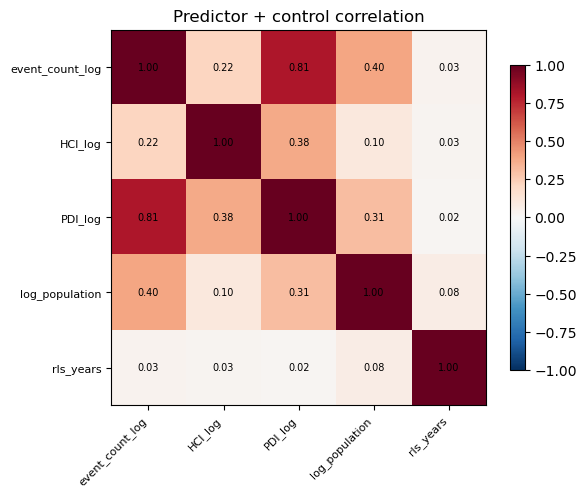

In [64]:
# ═════════════════════════════════════════════════════════════
# STEP 8 — Correlation + VIF (predictor-predictor) and X-Y (predictor-outcome)
# ═════════════════════════════════════════════════════════════
def vif_table(df, cols):
    X = df[cols].dropna().values
    X = (X - X.mean(0)) / (X.std(0) + 1e-12)
    return pd.Series(np.diag(inv(np.corrcoef(X, rowvar=False))), index=cols)

# Uses df_after (the TRANSFORMED, model-ready frame) — every column here is
# a treated variable. Names pulled from MODEL_VARS. VIF uses X only:
# flood predictors + continuous controls (NOT outcomes).
design = MODEL_VARS["flood_predictors"] + MODEL_VARS["controls"]

# (a) predictor + control correlation
print("(a) Correlation — flood predictors (log) + controls:\n")
corr = df_after[design].corr()
print(corr.round(2).to_string())

# (b) VIF (multicollinearity)
print("\n(b) VIF  (<5 keep all · 5–10 caution · >10 serious):")
print(vif_table(df_after, design).round(2).to_string())

# (c) X–Y correlation — EXPLORATORY ONLY (the FE regression is the result)
print("\n(c) Flood predictors × outcomes — raw bivariate (PRE-FE, exploratory):\n")
xy = df_after[MODEL_VARS["flood_predictors"] + MODEL_VARS["outcomes"]].corr()
print(xy.loc[MODEL_VARS["flood_predictors"], MODEL_VARS["outcomes"]].round(3).to_string())

# (d) heatmap of the predictor+control matrix
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(design))); ax.set_yticks(range(len(design)))
ax.set_xticklabels(design, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(design, fontsize=8)
for i in range(len(design)):
    for j in range(len(design)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Predictor + control correlation")
plt.tight_layout(); plt.show()

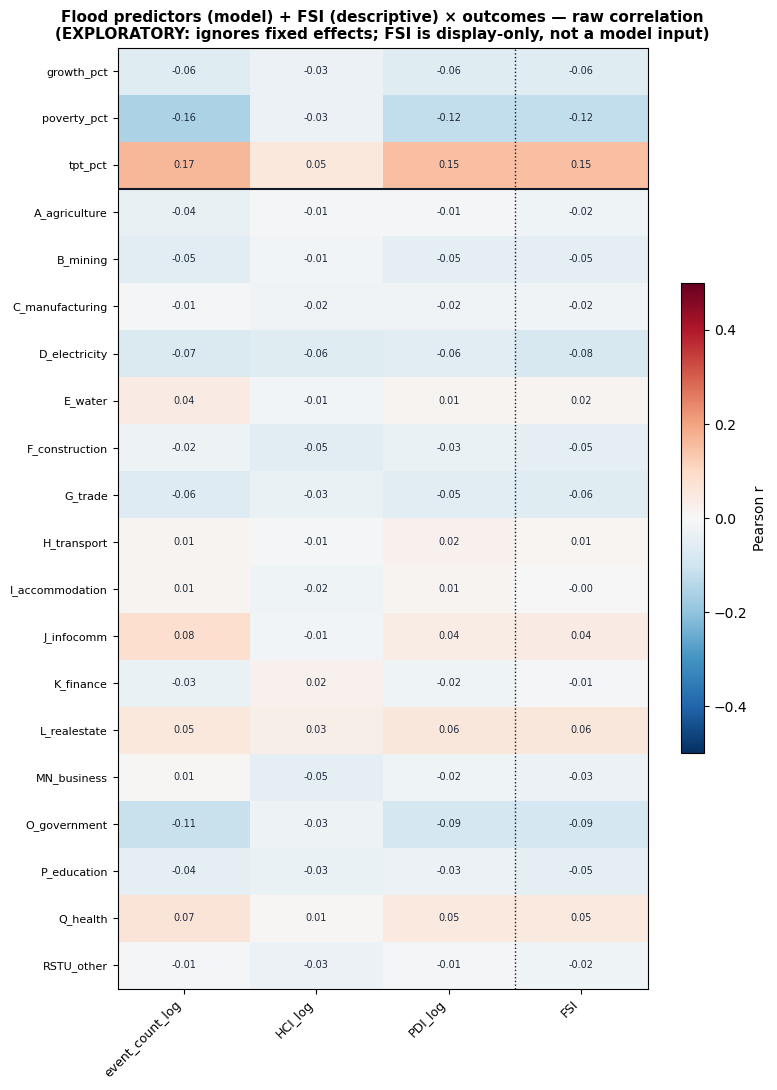

Strongest raw correlations (outcomes vs flood predictors + FSI):

                             event_count_log  HCI_log  PDI_log    FSI
tpt_pct                                0.166    0.053    0.152  0.150
poverty_pct                           -0.159   -0.029   -0.122 -0.124
grdp_O_government_growth              -0.111   -0.026   -0.086 -0.090
grdp_J_infocomm_growth                 0.083   -0.013    0.038  0.041
grdp_D_electricity_growth             -0.073   -0.062   -0.058 -0.080
grdp_Q_health_growth                   0.066    0.005    0.047  0.047
grdp_G_trade_growth                   -0.064   -0.034   -0.051 -0.061
grdp_growth_pct                       -0.062   -0.028   -0.062 -0.062
grdp_L_realestate_growth               0.053    0.031    0.056  0.057
grdp_F_construction_growth            -0.025   -0.055   -0.032 -0.048
grdp_B_mining_growth                  -0.053   -0.013   -0.047 -0.045
grdp_MN_business_growth                0.007   -0.051   -0.021 -0.030
grdp_P_education_growth 

In [65]:
# ═════════════════════════════════════════════════════════════
# STEP 8 — Full X-Y correlation heatmap (flood predictors + FSI x all outcomes)
# ═════════════════════════════════════════════════════════════
# EXPLORATORY ONLY. Raw bivariate correlation — does NOT control for regency/year
# fixed effects, so it is NOT the regression result. FSI is included here as a
# DESCRIPTIVE composite (it is used for dashboard display, not in the models),
# alongside the LOG flood predictors (event_count_log/HCI_log/PDI_log) the FE regression uses.
# x = flood predictors (log) + FSI composite (descriptive)
# X = flood predictors (from MODEL_VARS) + FSI (descriptive only, not a model input)
x_vars = MODEL_VARS["flood_predictors"] + ["FSI"]
y_vars = MODEL_VARS["outcomes"] + MODEL_VARS["sector_outcomes"]

# correlation of each y with each x
# model vars come from df_after (transformed); FSI is descriptive (from panel)
_hm = df_after[MODEL_VARS["flood_predictors"] + y_vars].copy()
_hm["FSI"] = panel["FSI"].values
cmat = _hm[x_vars + y_vars].corr().loc[y_vars, x_vars]

fig, ax = plt.subplots(figsize=(8, 11))
im = ax.imshow(cmat.values, cmap="RdBu_r", vmin=-0.5, vmax=0.5, aspect="auto")
ax.set_xticks(range(len(x_vars)))
ax.set_xticklabels(x_vars, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(y_vars)))
ax.set_yticklabels([y.replace("grdp_", "").replace("_growth", "") for y in y_vars], fontsize=8)
# annotate each cell
for i in range(len(y_vars)):
    for j in range(len(x_vars)):
        v = cmat.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.3 else "#1e293b")
# separate headline outcomes from sectors
ax.axhline(len(MODEL_VARS["outcomes"]) - 0.5, color="#111827", lw=1.5)
# visually mark FSI as the descriptive composite (last column)
ax.axvline(len(x_vars) - 1.5, color="#111827", lw=1.0, ls=":")
plt.colorbar(im, ax=ax, shrink=0.5, label="Pearson r")
ax.set_title("Flood predictors (model) + FSI (descriptive) × outcomes — raw correlation\n"
             "(EXPLORATORY: ignores fixed effects; FSI is display-only, not a model input)",
             fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

# numeric table, sorted by strongest |correlation| with any flood predictor
cmat_sorted = cmat.reindex(cmat.abs().max(axis=1).sort_values(ascending=False).index)
print("Strongest raw correlations (outcomes vs flood predictors + FSI):\n")
print(cmat_sorted.round(3).to_string())
print("""
  Reminder: these are RAW correlations across all regency-years, dominated by
  between-regency differences. The FE regression (nb9) strips those out, so a
  correlation visible here can vanish in the model (and vice versa). FSI is shown
  for descriptive comparison only — it is the dashboard composite, NOT a model
  predictor (the models use the LOG forms event_count_log/HCI_log/PDI_log). Treat this whole
  map as co-movement, not evidence of effect.""")

## STEP 9 — Panel diagnostics before fixed-effects estimation

Within-regency variation is make-or-break for two-way fixed effects (the flood
effects are identified only from within-regency, over-time variation). Controls
such as `rls_years` show low within-variation — expected, not a bug.

In [68]:
# ═════════════════════════════════════════════════════════════
# STEP 9 — Panel diagnostics before FE regression
# ═════════════════════════════════════════════════════════════
# (a) Balance
counts = df_after.groupby("bps_kab_code")["year"].nunique()
print(f"(a) Balance: {(counts==10).sum()}/{df_after['bps_kab_code'].nunique()} regencies "
      f"have all 10 years → {'BALANCED' if (counts==10).all() else 'UNBALANCED'}")

# (b) Missing in model variables
mvars = MODEL_VARS["flood_predictors"] + MODEL_VARS["outcomes"] + MODEL_VARS["controls"]
print("\n(b) Missing in model variables:")
miss = panel[mvars].isna().sum()
print(miss[miss > 0].to_string() if miss.sum() else "    none")

# (c) Within-regency variation — the assumption two-way FE depends on
print("\n(c) Within-regency variation (FE identifies effects from this):")
for v in MODEL_VARS["flood_predictors"] + MODEL_VARS["controls"] + MODEL_VARS["outcomes"]:
    overall = df_after[v].std()
    within  = df_after.groupby("bps_kab_code")[v].transform(lambda s: s - s.mean()).std()
    print(f"    {v:<20} overall={overall:8.3f}  within={within:8.3f}  ({within/overall*100:4.0f}% within)")

# (d) Outcome extremes after winsorising
print("\n(d) Outcome extremes (post-winsor):")
for y in MODEL_VARS["outcomes"]:
    q = panel[y].quantile([0.01, 0.5, 0.99])
    print(f"    {y:<20} p1={q.iloc[0]:8.2f}  median={q.iloc[1]:7.2f}  p99={q.iloc[2]:8.2f}")

(a) Balance: 514/514 regencies have all 10 years → BALANCED

(b) Missing in model variables:
    none

(c) Within-regency variation (FE identifies effects from this):
    event_count_log      overall=   0.813  within=   0.580  (  71% within)
    HCI_log              overall=   1.001  within=   0.924  (  92% within)
    PDI_log              overall=   4.771  within=   3.637  (  76% within)
    log_population       overall=   1.023  within=   0.073  (   7% within)
    rls_years            overall=   1.665  within=   0.347  (  21% within)
    grdp_growth_pct      overall=   2.580  within=   2.324  (  90% within)
    poverty_pct          overall=   0.534  within=   0.077  (  14% within)
    tpt_pct              overall=   0.444  within=   0.196  (  44% within)

(d) Outcome extremes (post-winsor):
    grdp_growth_pct      p1=   -4.25  median=   4.79  p99=   12.54
    poverty_pct          p1=    1.27  median=   2.40  p99=    3.65
    tpt_pct              p1=    0.39  median=   1.65  p99=    

## STEP 10 — National choropleth (dashboard preview)

Growth as a diverging colour, FSI as a sqrt-scaled bubble, using the same GPKG
geometry as the dashboard. The FSI here is purely descriptive display; it is not
a model input.

  Polygons matched: 514/514 (0 no data)


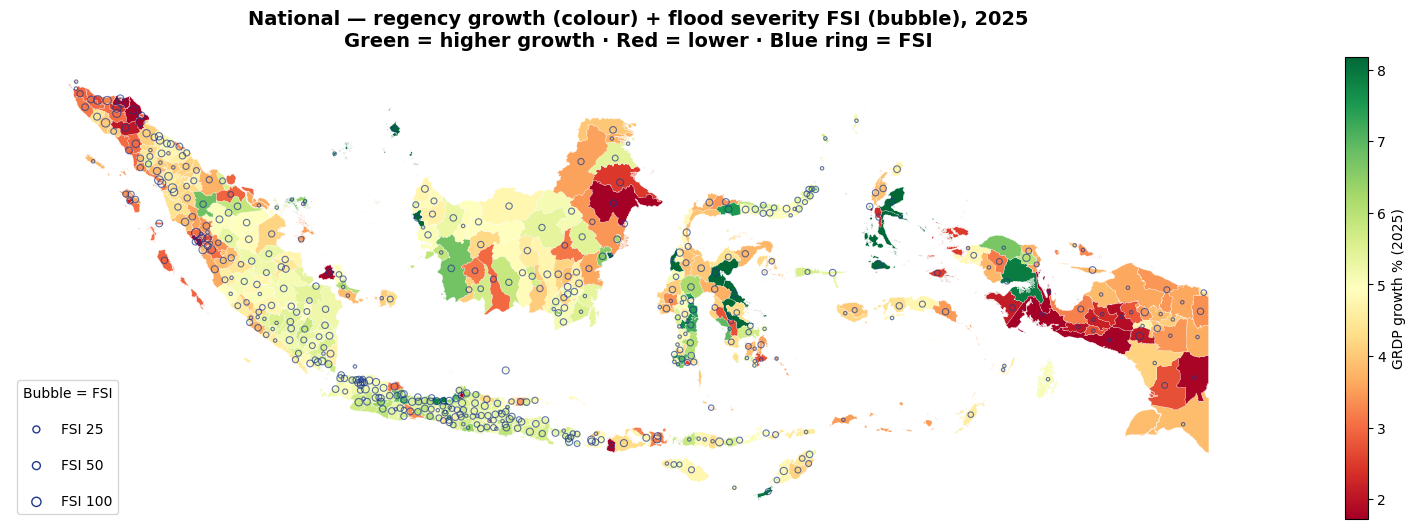

In [70]:
# ═════════════════════════════════════════════════════════════
# STEP 10 — National choropleth (GPKG polygons): growth colour + FSI bubble
# ═════════════════════════════════════════════════════════════
# Dashboard preview, latest year. Growth = diverging colour saturation (no
# zones); FSI = sqrt-scaled bubble (area ∝ FSI). Same geometry as the dashboard.
year_show = panel["year"].max()
snap = panel[panel["year"] == year_show].copy()

gdf_geo = gpd.read_file(GPKG_PATH)
gdf_geo["bps_kab_code"] = pd.to_numeric(gdf_geo["bps_kab_code"], errors="coerce").astype("Int64")
snap["bps_kab_code"] = snap["bps_kab_code"].astype("Int64")
gmap = gdf_geo.merge(
    snap[["bps_kab_code", "grdp_growth_pct", "FSI_index", "centroid_lat", "centroid_lon"]],
    on="bps_kab_code", how="left")
matched = gmap["grdp_growth_pct"].notna().sum()
print(f"  Polygons matched: {matched}/{len(gmap)} ({len(gmap)-matched} no data)")

fig, ax = plt.subplots(figsize=(16, 8))
vlo, vhi = snap["grdp_growth_pct"].quantile([.02, .98])
gmap.plot(column="grdp_growth_pct", cmap="RdYlGn", vmin=vlo, vmax=vhi,
          linewidth=0.15, edgecolor="white", ax=ax,
          missing_kwds={"color": "#f3f4f6", "edgecolor": "#cbd5e1", "label": "No data"},
          legend=True, legend_kwds={"label": f"GRDP growth % ({year_show})", "shrink": 0.6})
size = 6 + 38 * np.sqrt(snap["FSI_index"].clip(0, 100) / 100)   # area ∝ FSI
ax.scatter(snap["centroid_lon"], snap["centroid_lat"], s=size,
           facecolor="none", edgecolor="#1e3a8a", linewidth=0.8, alpha=0.7)
ax.set_title(f"National — regency growth (colour) + flood severity FSI (bubble), {year_show}\n"
             "Green = higher growth · Red = lower · Blue ring = FSI",
             fontsize=14, fontweight="bold")
ax.set_axis_off()
for fsi_demo in [25, 50, 100]:
    ax.scatter([], [], facecolor="none", edgecolor="#1e3a8a",
               s=6 + 38*np.sqrt(fsi_demo/100), label=f"FSI {fsi_demo}")
ax.legend(scatterpoints=1, title="Bubble = FSI", loc="lower left", labelspacing=1.6)
plt.tight_layout(); plt.show()

## STEP 11 — Export the model-ready panel

Export two stand-alone sheets, each with full identifiers:
- **`transformed`** (`df_after`) — model-ready columns (`MODEL_VARS`). **Notebooks 9-11 load this.**
- **`pre_transform`** (`df_before`) — original/raw variables, joined in only when a robustness check needs raw values.

Plus a `metadata` sheet documenting the build and the join pattern, and the
descriptive-statistics appendix (`appendix_descriptive_stats.tex`).

In [72]:
# ═════════════════════════════════════════════════════════════
# STEP 11 — Export the model-ready panel
# ═════════════════════════════════════════════════════════════
# EXPORT two sheets -> 8_panel_data.xlsx
#   sheet "transformed"   = df_after  (model-ready; loaded by nb9/nb10/nb11)
#   sheet "pre_transform" = df_before (original/raw; joined in for robustness)
# Both sheets carry full identifiers so each stands alone and can be joined on
# bps_kab_code + year when a notebook needs to compare treated vs raw.
# ═════════════════════════════════════════════════════════════════════════════

# metadata documenting the build + how to use the two sheets
meta = pd.DataFrame({
    "item": [
        "rows", "regencies", "years",
        "sheet:transformed", "sheet:pre_transform",
        "join_keys", "model_input",
        "flood_predictors", "outcomes", "sector_outcomes", "controls",
        "note_HCI_PDI", "note_robustness",
    ],
    "value": [
        len(df_after), df_after["bps_kab_code"].nunique(), df_after["year"].nunique(),
        f"{df_after.shape[1]} cols — identifiers + MODEL_VARS (treated, model-ready)",
        f"{df_before.shape[1]} cols — identifiers + original/raw variables",
        "bps_kab_code + year",
        "nb9/nb10/nb11 load 'transformed'; join 'pre_transform' only for raw comparisons",
        ", ".join(MODEL_VARS["flood_predictors"]),
        ", ".join(MODEL_VARS["outcomes"]),
        f"{len(MODEL_VARS['sector_outcomes'])} sector growth rates",
        ", ".join(MODEL_VARS["controls"]),
        "HCI_log/PDI_log are nb6 log-sum indices (already logged); pre_transform holds same as HCI/PDI",
        "winsorised-vs-raw: load both sheets, join on keys, compare *_raw from pre_transform",
    ],
})

with pd.ExcelWriter(OUT_PATH, engine="openpyxl") as xl:
    df_after.to_excel(xl,  sheet_name="transformed",   index=False)
    df_before.to_excel(xl, sheet_name="pre_transform", index=False)
    meta.to_excel(xl,      sheet_name="metadata",       index=False)

print(f"Exported {OUT_PATH}")
print(f"  sheet 'transformed'   : {df_after.shape[1]} cols × {len(df_after)} rows  (→ nb9/10/11)")
print(f"  sheet 'pre_transform' : {df_before.shape[1]} cols × {len(df_before)} rows  (raw reference)")
print(f"  sheet 'metadata'      : build decisions + join guide")
print("\nDownstream load pattern:")
print('  transformed  = pd.read_excel("8_panel_data.xlsx", sheet_name="transformed")')
print('  # for robustness only:')
print('  pre          = pd.read_excel("8_panel_data.xlsx", sheet_name="pre_transform")')
print('  merged       = transformed.merge(pre, on=["bps_kab_code","year"], suffixes=("","_pre"))')

Exported ../data/processed/8_panel_data.xlsx
  sheet 'transformed'   : 30 cols × 5140 rows  (→ nb9/10/11)
  sheet 'pre_transform' : 36 cols × 5140 rows  (raw reference)
  sheet 'metadata'      : build decisions + join guide

Downstream load pattern:
  transformed  = pd.read_excel("8_panel_data.xlsx", sheet_name="transformed")
  # for robustness only:
  pre          = pd.read_excel("8_panel_data.xlsx", sheet_name="pre_transform")
  merged       = transformed.merge(pre, on=["bps_kab_code","year"], suffixes=("","_pre"))


## Summary and next steps

**Built:** a 514 x 10 balanced analysis panel (5,140 regency-year observations)
with the flood predictors in Notebook 6 log/z forms, winsorised outcomes (plus
raw twins), 17 sector growth rates, treatment flags, and the dashboard crosswalk
→ `8_panel_data.xlsx`.

**Workflow followed:** load → diagnose before → transform → diagnose after →
summary → analysis. Every treatment is justified by a before/after skewness and
outlier comparison, not applied by default.

**Next:**
- **Notebook 9** — fixed-effects regression: GRDP growth and the 17 sectors.
- **Notebook 10** — fixed-effects regression: poverty and unemployment.
- **Notebook 11** — XGBoost + SHAP (predictive complement).

Each downstream notebook opens with a transform guard that re-verifies the
single-log flood forms before modelling.

In [83]:
# ═════════════════════════════════════════════════════════════
# STEP 11 — Export the descriptive-statistics appendix
# ═════════════════════════════════════════════════════════════
# Appendix: descriptive statistics for all panel variables.
# Runs AFTER the final panel (FEATURES/CONTROLS/outcomes all present) is built.
# Output: ../figures/appendix_descriptive_stats.tex
import pandas as pd
from pathlib import Path

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

assert "panel" in dir(), "panel dataframe not found -- run the panel construction cells first."

# [ACTION ITEM] Adjust this list/labels if your final panel uses different
# column names. Each tuple: (column_name, display_label, source_note).
VARS = [
    ("event_count",        "Flood event frequency",     "BNPB"),
    ("HCI",                "Human Casualty Index",      "BNPB (derived)"),
    ("PDI",                "Physical Damage Index",     "BNPB (derived)"),
    ("FSI",                "Flood Severity Index",      "Derived"),
    ("grdp_growth_pct",    "GRDP growth (\\%)",          "BPS"),
    ("poverty_pct",        "Poverty rate (\\%)",         "BPS"),
    ("tpt_pct",            "Open unemployment rate (\\%)","BPS"),
    ("population",         "Population",                 "BPS"),
    ("rls_years",          "Mean years of schooling",   "BPS"),
]

rows = []
for col, label, source in VARS:
    if col not in panel.columns:
        print(f"  WARNING: column '{col}' not found in panel -- skipping '{label}'")
        continue
    s = panel[col].dropna()
    rows.append({
        "Variable": label,
        "Source": source,
        "Mean": s.mean(),
        "SD": s.std(),
        "Min": s.min(),
        "Max": s.max(),
        "N": len(s),
    })

desc = pd.DataFrame(rows)
print(desc.to_string(index=False, float_format=lambda x: f"{x:,.2f}"))

def _fmt(x):
    return f"{x:,.2f}"

tex_rows = []
for _, row in desc.iterrows():
    tex_rows.append(
        f"{row['Variable']} & {row['Source']} & {_fmt(row['Mean'])} & "
        f"{_fmt(row['SD'])} & {_fmt(row['Min'])} & {_fmt(row['Max'])} & "
        f"{int(row['N']):,} \\\\"
    )

tex_table = (
    r"\begin{tabular*}{\textwidth}{@{\extracolsep{\fill}}llrrrrr@{}}" "\n"
    r"\toprule" "\n"
    r"\textbf{Variable} & \textbf{Source} & \textbf{Mean} & \textbf{SD} & "
    r"\textbf{Min} & \textbf{Max} & \textbf{N} \\" "\n"
    r"\midrule" "\n"
    + "\n".join(tex_rows) + "\n"
    r"\bottomrule" "\n"
    r"\end{tabular*}" "\n"
)

out_tex = FIG_DIR / "appendix_descriptive_stats.tex"
out_tex.write_text(tex_table, encoding="utf-8")
print(f"\nSaved: {out_tex}")
print("\n--- Preview ---")
print(tex_table)

                   Variable         Source       Mean         SD       Min          Max    N
      Flood event frequency           BNPB       2.54       3.71      0.00        69.00 5140
       Human Casualty Index BNPB (derived)       0.27       1.00      0.00        15.97 5140
      Physical Damage Index BNPB (derived)       4.76       4.77      0.00        28.64 5140
       Flood Severity Index        Derived      -0.00       0.80     -0.76         7.02 5140
           GRDP growth (\%)            BPS       4.19       2.58     -4.25        12.61 5140
          Poverty rate (\%)            BPS       2.42       0.53      0.98         3.83 5140
Open unemployment rate (\%)            BPS       1.64       0.44      0.00         2.85 5140
                 Population            BPS 527,945.51 636,127.75 13,975.00 5,873,530.00 5140
    Mean years of schooling            BPS       8.38       1.67      0.70        13.37 5140

Saved: ..\figures\appendix_descriptive_stats.tex

--- Preview ---
\be